# Synthetic experiment geometries

The four original networks share a **20 km domain**: 5 km approach, 10 km test section, and 5 km exit. This notebook plots their geometry and identifies the nested/overlapping units using the repository's unit detector.

Lateral positions and curves are **schematic**. Baseline routing length is downstream x-span; drawn curvature does not add length. Line thickness indicates prescribed width. Parent–child panels show analytically collapsed synthetic geometries. Selected corridors become a single path, retaining external attachments at their downstream stations and summing selected widths at each station. These baseline examples do not run the raster-based collapse workflow.

Run all cells using the `river-hierarchy-rivgraph` Python environment. No routing runs or legacy imports are required.

**Current synthetic version · 30 September 2026:** BASED reference depth, local width–depth exponent **α=0.65**, Manning n=0.035, X=0.1 and 200m segmentation/floor. Responses and local-kb resistance are recomputed from the versioned routing run. Geometry and validation partitions are unchanged. **Real-case comparison is deferred until the updated-slope runs.** Earlier outputs are preserved separately; the old-versus-new comparison changes the complete hydraulic setup, not alpha alone.
The geometric construction is unchanged; this notebook does not route hydrographs.

In [1]:
from pathlib import Path
import sys

# Works from the repository root or this notebook's directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "synthetic_experiments" / "src").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the river-hierarchy repository")
for path in (ROOT, ROOT / "synthetic_experiments" / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from synthetic_experiments.design import Design, FAMILIES, build_original, planned_states
from synthetic_experiments.plotting import plot_network
from hierarchy_level_definition.unit_detection.bifurcation_confluence_units import build_structural_units

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

## Shared parameters

Width and total head drop below are editable starter values. `inner_fraction` controls the first inner branch in the nested case and the fraction of branch A transferred through the crossover. All length multipliers start at one.

In [2]:
design = Design(
    total_width_m=500.0,
    head_drop_m=2.0,
    outer_a_fraction=0.8,
    inner_fraction=0.5,
)
networks = {family: build_original(family, design) for family in FAMILIES}
names = {"centerline": "Single centerline", "simple": "Simple unit",
         "nested": "Nested unit", "crossover": "Crossover / compound"}

rows = []
for family, net in networks.items():
    rows.append({"Geometry": names[family], "Structural edges": net.G.number_of_edges(),
                 "Baseline sum WL (m²)": sum(d["w"] * d["length_m"] for *_, d in net.G.edges(data=True)),
                 "Head drop (m)": design.head_drop_m})
display(pd.DataFrame(rows).set_index("Geometry"))

,Structural edges,Baseline sum WL (m²),Head drop (m)
Geometry,,,
Single centerline,3,10000000.0,2.0
Simple unit,4,10000000.0,2.0
Nested unit,7,10000000.0,2.0
Crossover / compound,7,10000000.0,2.0


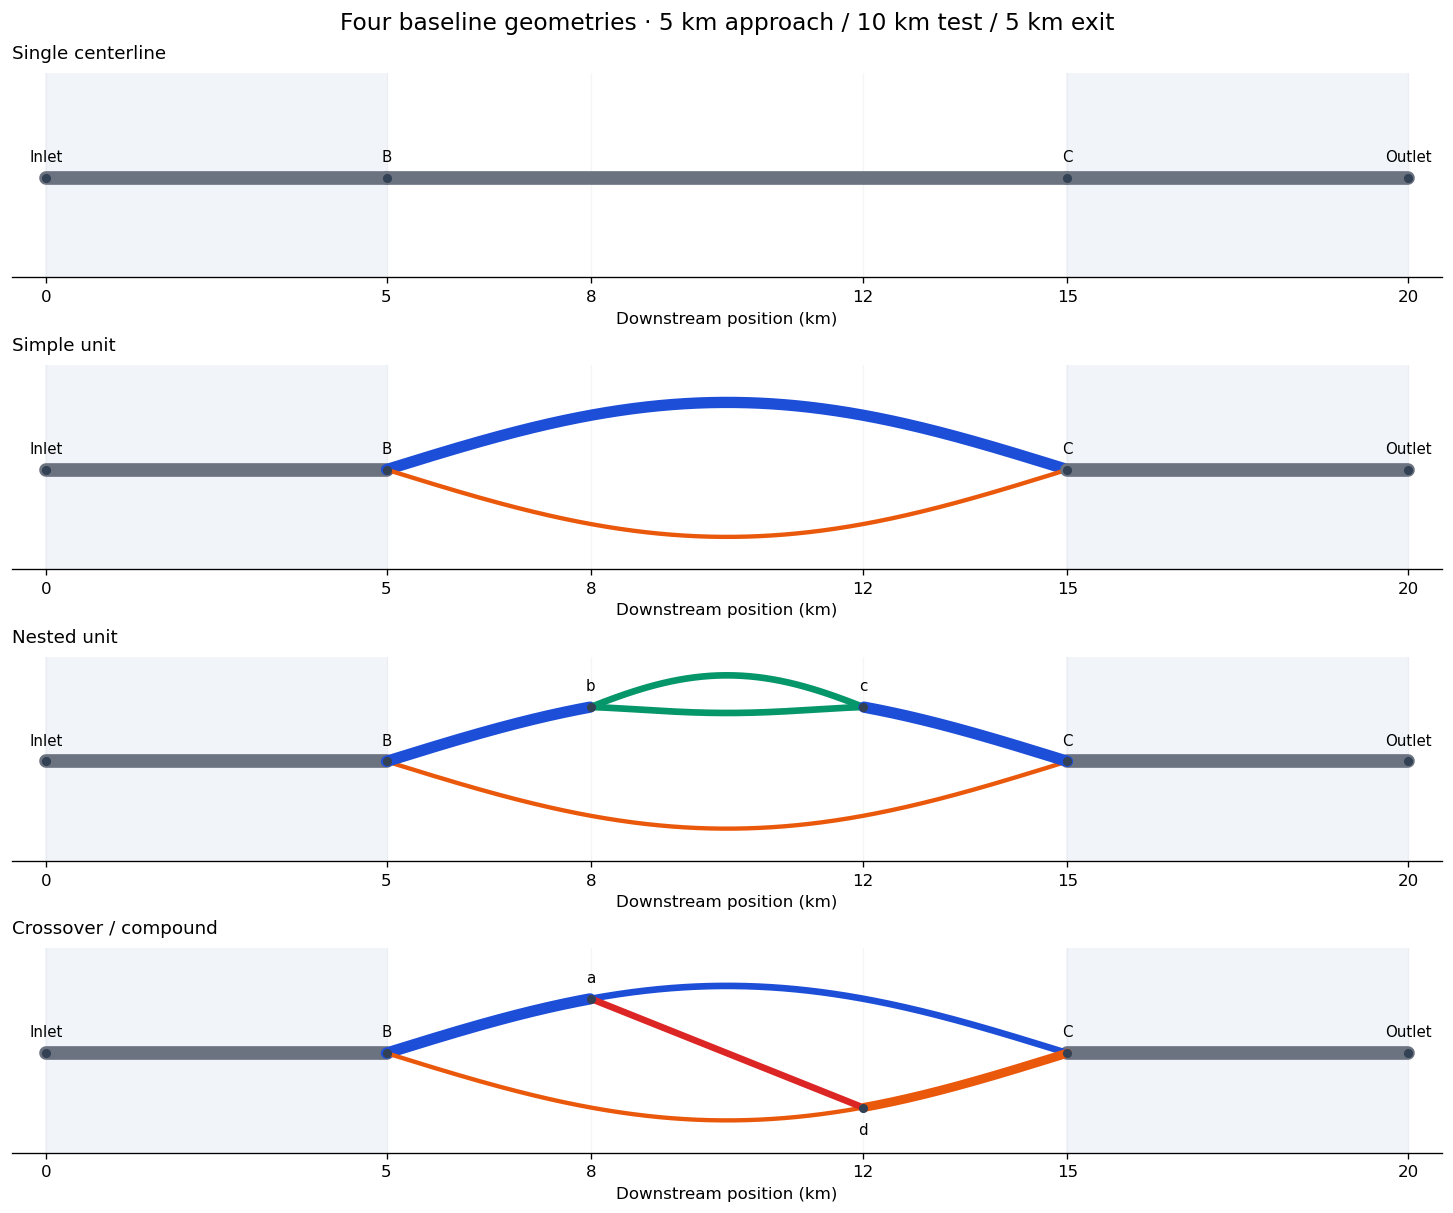

In [3]:
# Reuse the new package's existing Plotly geometry traces for static notebook
# figures. These figures remain visible in notebook previews without JavaScript.
def draw_network(ax, family, *, selected=None, title=None, label_nodes=True):
    net = networks[family]
    source = plot_network(net, show_nodes=False)
    edges = list(net.G.edges(keys=True, data=True))
    ax.axvspan(0, 5, color="#f1f5f9", zorder=0)
    ax.axvspan(15, 20, color="#f1f5f9", zorder=0)
    for trace, (u, v, k, data) in zip(source.data, edges):
        active = selected is None or (u, v, k) in selected
        color = trace.line.color if selected is None else ("#2563eb" if active else "#cbd5e1")
        ax.plot(np.asarray(trace.x)/1000, trace.y, color=color,
                lw=1.2 + 7*data["w"]/design.total_width_m,
                solid_capstyle="round", zorder=3 if active else 2)
    node_trace = plot_network(net).data[-1]
    xs, ys = np.asarray(node_trace.x)/1000, np.asarray(node_trace.y)
    ax.scatter(xs, ys, s=20, c="#334155", zorder=5)
    for node, x, y in zip(net.G.nodes, xs, ys):
        position, tag = node
        label = {0: "Inlet", 5000: "B", 15000: "C", 20000: "Outlet"}.get(position)
        if position == 8000:
            label = "b" if family == "nested" else "a"
        elif position == 12000:
            label = "c" if family == "nested" else "d"
        if label_nodes and label:
            ax.annotate(label, (x,y), xytext=(0, 10 if y >= 0 else -16),
                        textcoords="offset points", ha="center", fontsize=9)
    ax.set(xlim=(-0.5,20.5), ylim=(-3.7,3.9), yticks=[],
           xticks=[0,5,8,12,15,20], xlabel="Downstream position (km)")
    ax.set_title(title or names[family], loc="left", fontsize=11, pad=9)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", alpha=0.12)


def detected_units(family):
    net = networks[family]
    node_ids = {n:i for i,n in enumerate(net.G.nodes)}
    graph = nx.MultiDiGraph()
    edge_lookup = {}
    for i, (u,v,k,d) in enumerate(net.G.edges(keys=True, data=True), 1):
        key = (node_ids[u], node_ids[v], i)
        graph.add_edge(*key[:2], key=i, id_link=i, length=d["length_m"])
        edge_lookup[key] = (u,v,k)
    units = build_structural_units(graph)
    return [(unit, {edge_lookup[e] for e in unit.edge_set}) for unit in units]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), constrained_layout=True)
for ax, family in zip(axes, FAMILIES):
    draw_network(ax, family)
fig.suptitle("Four baseline geometries · 5 km approach / 10 km test / 5 km exit", fontsize=14)
display(fig)
plt.close(fig)

In [4]:
from synthetic_experiments.collapse import drawable_graph, collapse_selected, nested_main_island_edges


def draw_child(ax, graph, title):
    ax.axvspan(0, 5, color="#f1f5f9", zorder=0)
    ax.axvspan(15, 20, color="#f1f5f9", zorder=0)
    for u,v,k,d in graph.edges(keys=True, data=True):
        ax.plot(np.asarray(d["plot_x"])/1000, d["plot_y"], color=d["color"],
                lw=1.2+7*d["w"]/design.total_width_m, solid_capstyle="round")
    junctions = [node for node in graph if graph.in_degree(node)>1 or graph.out_degree(node)>1]
    for node in junctions:
        d=graph.nodes[node]
        ax.scatter(d["x"]/1000,d["y"],s=20,c="#334155",zorder=5)
        ax.annotate(f'{d["x"]/1000:g} km', (d["x"]/1000,d["y"]),
                    xytext=(0,12),textcoords="offset points",ha="center",fontsize=9)
    ax.set(xlim=(-0.5,20.5),ylim=(-3.7,3.9),yticks=[],xticks=[0,5,8,12,15,20],
           xlabel="Downstream position (km)")
    ax.set_title(title,loc="left",fontsize=11,pad=9)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x",alpha=0.12)


def parent_child_panels(family, selections):
    original=drawable_graph(networks[family])
    fig, axes=plt.subplots(len(selections),2,figsize=(15,3.2*len(selections)),
                           squeeze=False,constrained_layout=True)
    children={}
    for (left,right),(label,selected) in zip(axes,selections):
        draw_network(left,family,selected=selected,title="Parent · selected collapse paths in blue")
        child=collapse_selected(original,selected)
        draw_child(right,child,"Child · "+label)
        children[label]=child
    display(fig)
    plt.close(fig)
    return children


## Simple unit: one child

Left: original parent with the selected unit in blue. Right: the collapsed child, with its replacement corridor in purple. Approach and exit reaches are preserved.

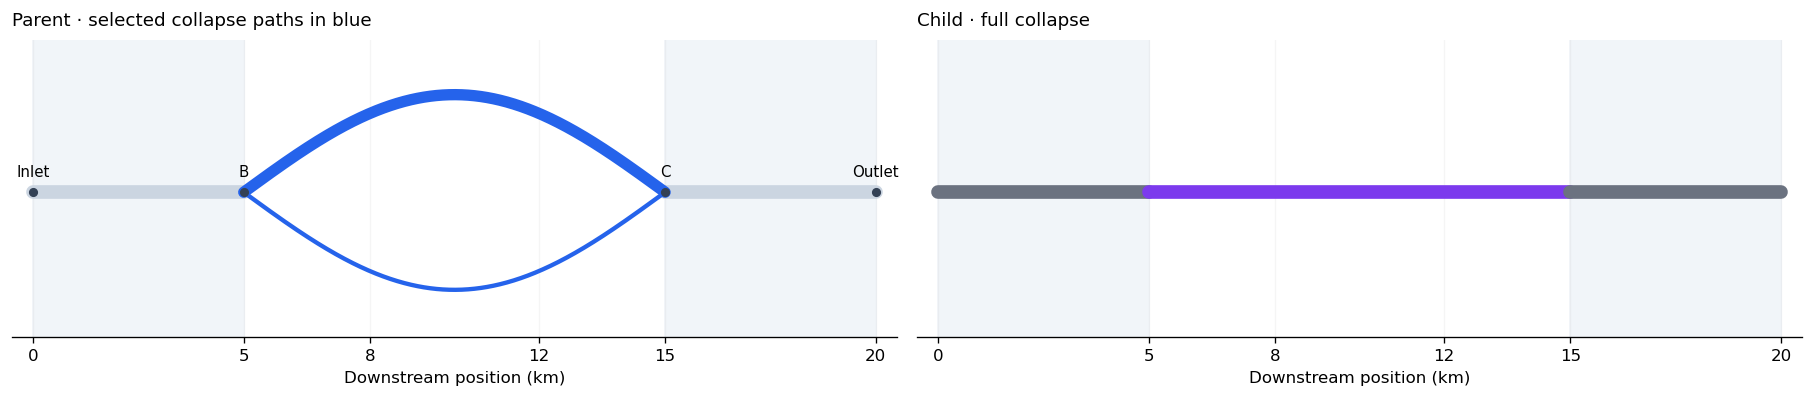

In [5]:
simple_units=detected_units("simple")
assert len(simple_units)==1
simple_children=parent_child_panels("simple",[("full collapse",simple_units[0][1])])

## Nested network: three children

All children are derived directly from the same original:

- **Inner collapse:** removes the small island and leaves the outer simple unit at 5–15 km.
- **Main-island collapse:** removes only the main island and leaves a simple unit around the small island at 8–12 km. The upper inner branch retains its width, physical length, slope and length multiplier; its node heads remain prescribed. The other surviving branch has width `W * (1 - outer_a_fraction * inner_fraction)`.
- **Full topological collapse:** removes both islands and leaves the centerline.

The main-island selection is the lower inner branch plus the outer corridor paths; it is not the complete outer topological unit. Resistance is compared over the enclosing 5–15 km domain, including the retained branch. All three alternatives are sibling states.

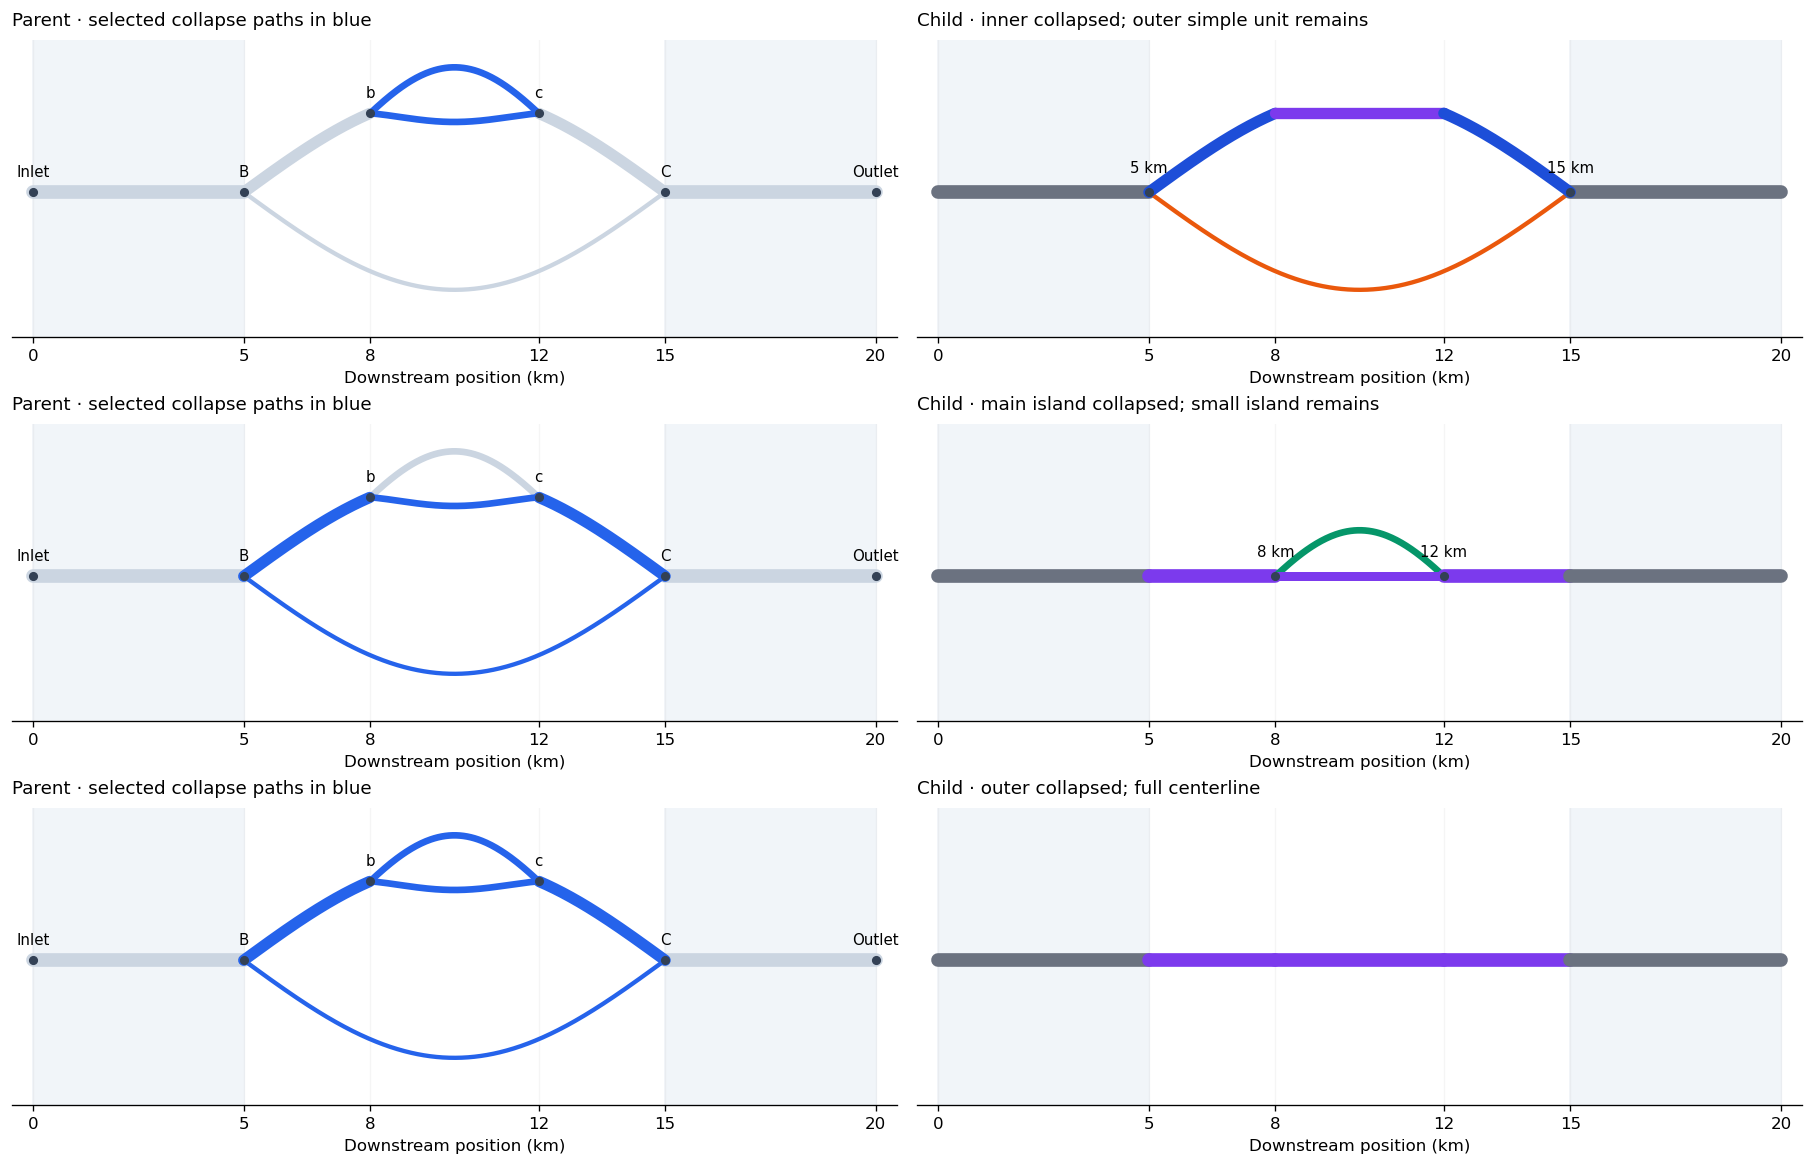

,start_km,end_km,width_m,length_m,slope
0,0.0,5.0,500.0,5000.0,0.0001
1,5.0,8.0,500.0,3000.0,0.0001
2,8.0,12.0,200.0,4000.0,0.0001
3,8.0,12.0,300.0,4000.0,0.0001
4,12.0,15.0,500.0,3000.0,0.0001
5,15.0,20.0,500.0,5000.0,0.0001


In [6]:
nested_units=sorted(detected_units("nested"),key=lambda item:len(item[1]),reverse=True)
assert len(nested_units)==2
assert nested_units[1][1] < nested_units[0][1]
nested_children=parent_child_panels("nested",[
    ("inner collapsed; outer simple unit remains",nested_units[1][1]),
    ("main island collapsed; small island remains",nested_main_island_edges(networks["nested"].G)),
    ("outer collapsed; full centerline",nested_units[0][1]),
])

main_child=nested_children["main island collapsed; small island remains"]
display(pd.DataFrame([dict(start_km=main_child.nodes[u]['x']/1000,
    end_km=main_child.nodes[v]['x']/1000,width_m=d['w'],length_m=d['length_m'],slope=d['slope'])
    for u,v,d in main_child.edges(data=True)]).sort_values(['start_km','end_km']))

## Crossover: three children

Each row starts from the same original. Independent upstream collapse leaves a simple unit from 8–15 km; independent downstream collapse leaves a simple unit from 5–12 km. Full compound collapse leaves a centerline.

These locations follow the analytical attachment rule: retain the downstream station of each surviving branch connection when projecting it onto the replacement corridor. This is an explicit synthetic construction, not a claim about the raster workflow's resulting coordinates.

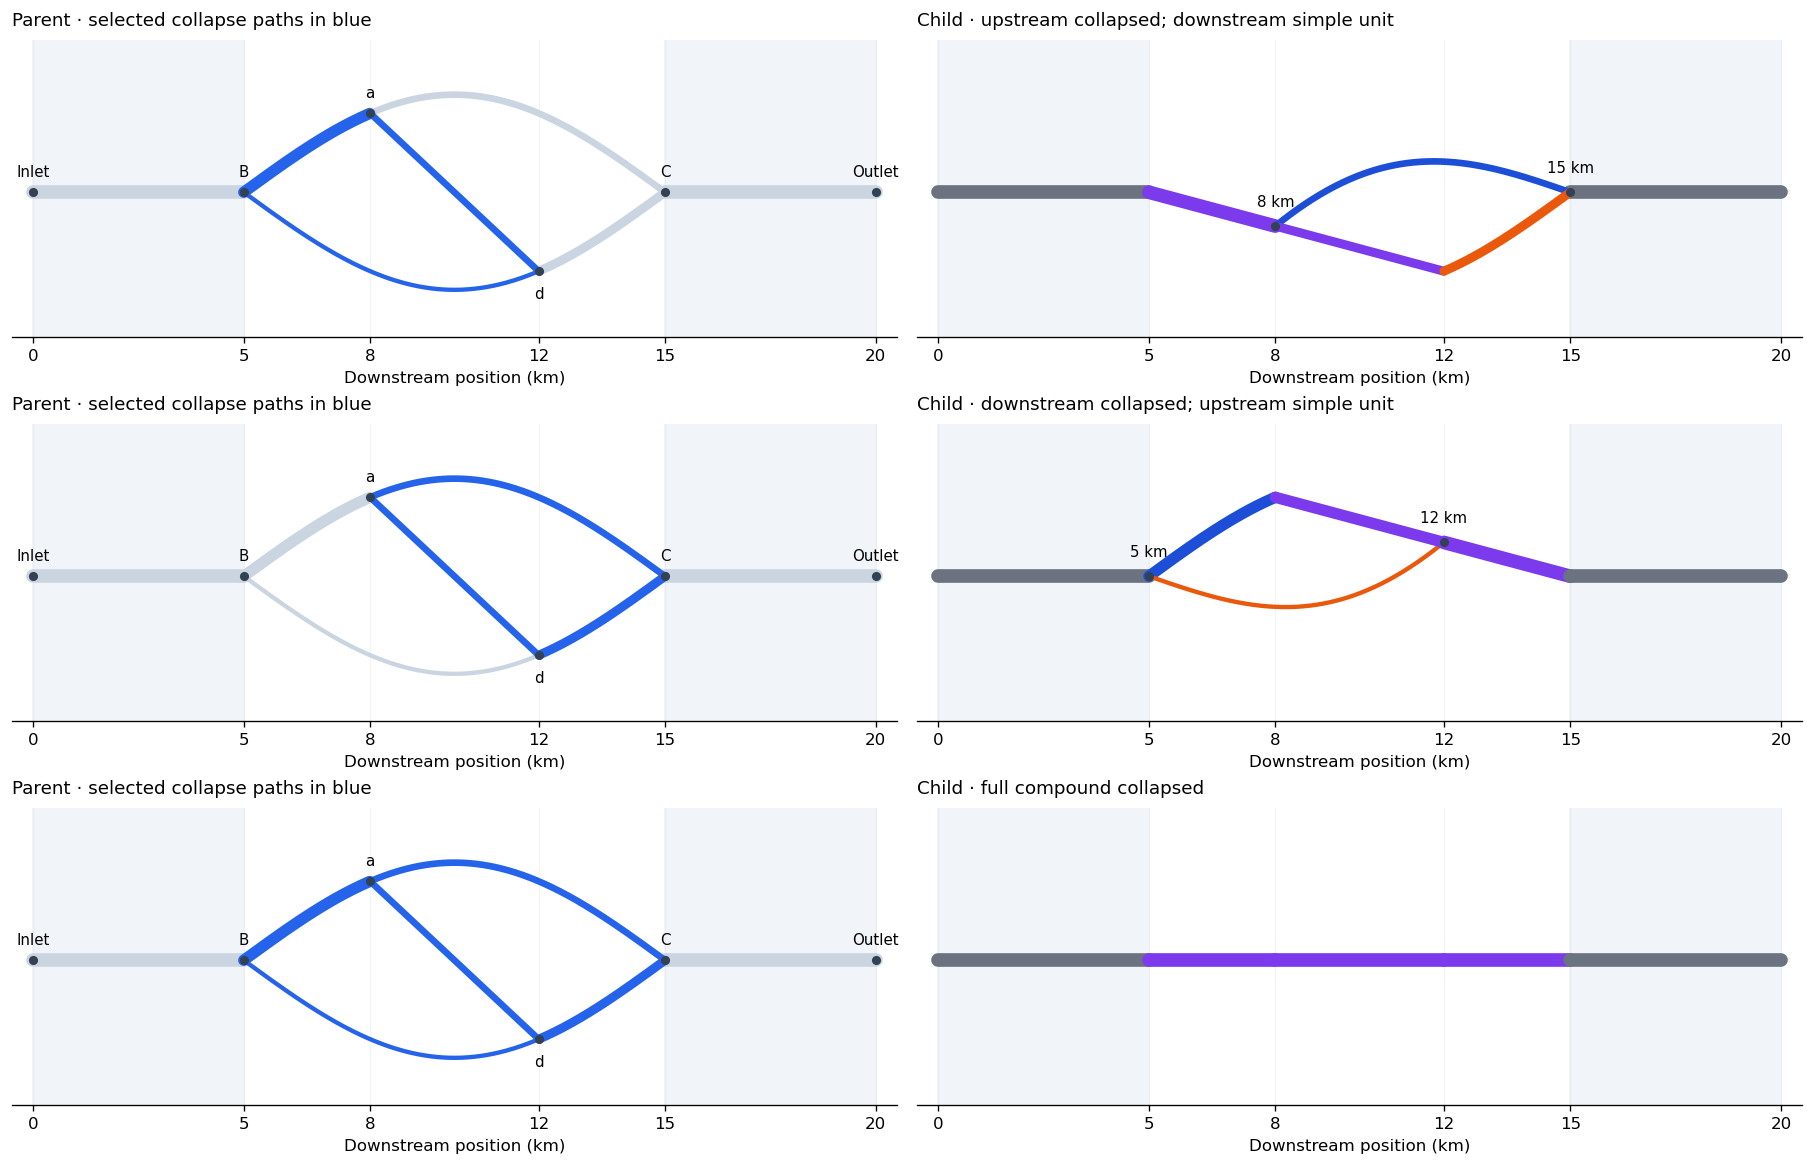

In [7]:
cross_units=sorted(detected_units("crossover"),
    key=lambda item:min(networks["crossover"].G.nodes[e[0]]["x"] for e in item[1]))
assert len(cross_units)==2
upstream,downstream=cross_units[0][1],cross_units[1][1]
assert len(upstream & downstream)==1
assert not upstream <= downstream and not downstream <= upstream
cross_children=parent_child_panels("crossover",[
    ("upstream collapsed; downstream simple unit",upstream),
    ("downstream collapsed; upstream simple unit",downstream),
    ("full compound collapsed",upstream | downstream),
])

## Common head profile and experiment lineage

Assign heads by downstream station: `H(x) = head_drop × (1 − x / 20,000)` with outlet head zero. Each edge slope is its endpoint head difference divided by its channel length. Thus every complete path has the same head drop, including after a length adjustment.

The table lists the four originals and seven directly compared children. Routing uses approximately 200 m segmentation. The completed extended grid is inspected in the routing, applicability and factor-interaction notebooks; this geometry notebook itself does not run routing.

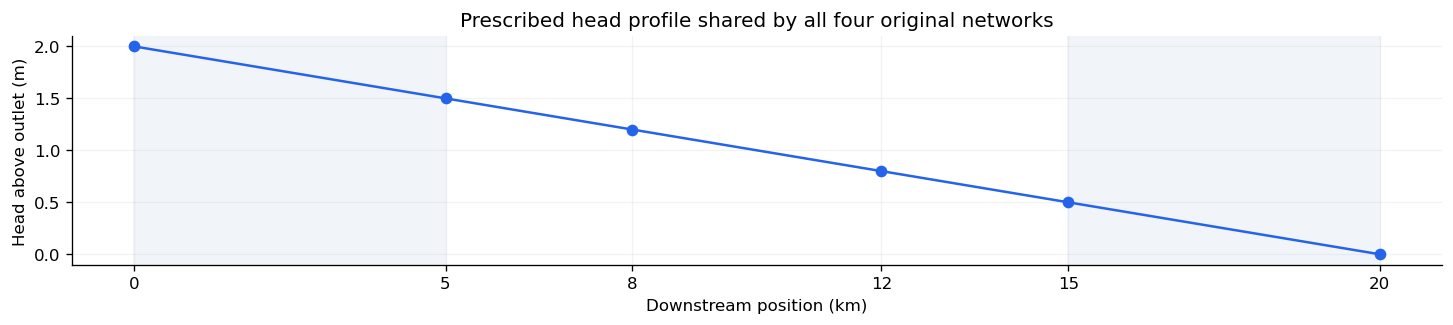

,family,state_id,parent_state_id,selection_type,selected_unit_labels,status
0,centerline,original,None,original,[],planned
1,simple,original,None,original,[],planned
2,simple,full,original,unit,[outer],planned
3,nested,original,None,original,[],planned
4,nested,inner_only,original,unit,[inner],planned
5,nested,main_island_only,original,island,[main_island],planned
6,nested,full,original,unit,[outer],planned
7,crossover,original,None,original,[],planned
8,crossover,upstream_only,original,unit,[upstream],planned
9,crossover,downstream_only,original,unit,[downstream],planned


In [8]:
fig, ax = plt.subplots(figsize=(12, 2.6), constrained_layout=True)
x = np.array([0, 5000, 8000, 12000, 15000, 20000])
heads = design.head_drop_m * (1-x/20000)
ax.plot(x/1000, heads, "o-", color="#2563eb")
ax.axvspan(0,5,color="#f1f5f9"); ax.axvspan(15,20,color="#f1f5f9")
ax.set(xlabel="Downstream position (km)", ylabel="Head above outlet (m)",
       xticks=x/1000, title="Prescribed head profile shared by all four original networks")
ax.grid(alpha=0.15)
display(fig)
plt.close(fig)

states = pd.DataFrame([s for family in FAMILIES
                       for s in planned_states(family, f"{family}_baseline")])
display(states[["family", "state_id", "parent_state_id", "selection_type",
                "selected_unit_labels", "status"]])

## Optional interactive geometry view

Use the existing Plotly helper for edge-width and length hover details. Change `family` below to any of `centerline`, `simple`, `nested`, or `crossover`.

In [9]:
family = "crossover"
interactive_figure = plot_network(networks[family], title=names[family])
interactive_figure.update_xaxes(title_text="Downstream position (m)")
interactive_figure.update_yaxes(title_text="Schematic lateral position")
# Uncomment for interactive display in a trusted notebook:
# interactive_figure.show()


Out[9]: 